<a href="https://colab.research.google.com/github/Kavishka2401/GPTea/blob/C_2_Disease_Detection/TeaLeafDiseaseDetectionSystem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


Mounted at /content/drive


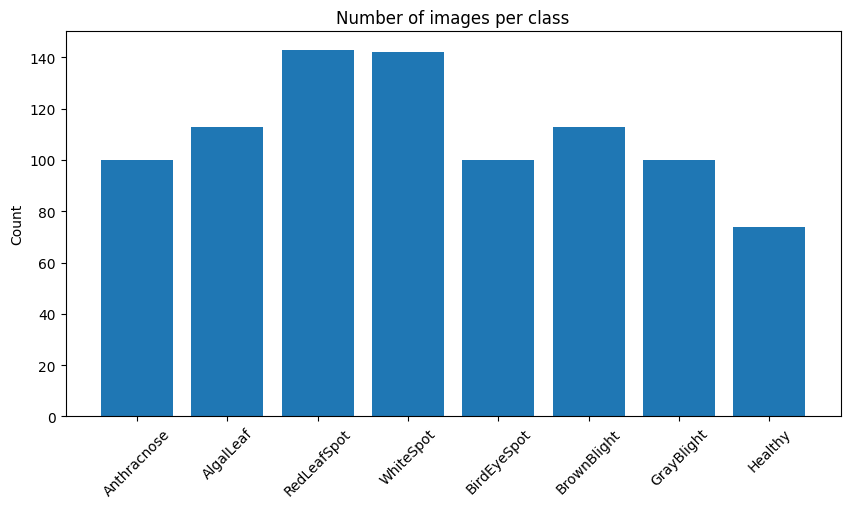

{'Anthracnose': 100,
 'AlgalLeaf': 113,
 'RedLeafSpot': 143,
 'WhiteSpot': 142,
 'BirdEyeSpot': 100,
 'BrownBlight': 113,
 'GrayBlight': 100,
 'Healthy': 74}

In [2]:

dataset_dir = "/content/drive/MyDrive/TeaDiseaseDataset"

class_counts = {}
for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if os.path.isdir(cls_path):
        class_counts[cls] = len(os.listdir(cls_path))

plt.figure(figsize=(10,5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45)
plt.title("Number of images per class")
plt.ylabel("Count")
plt.show()

class_counts


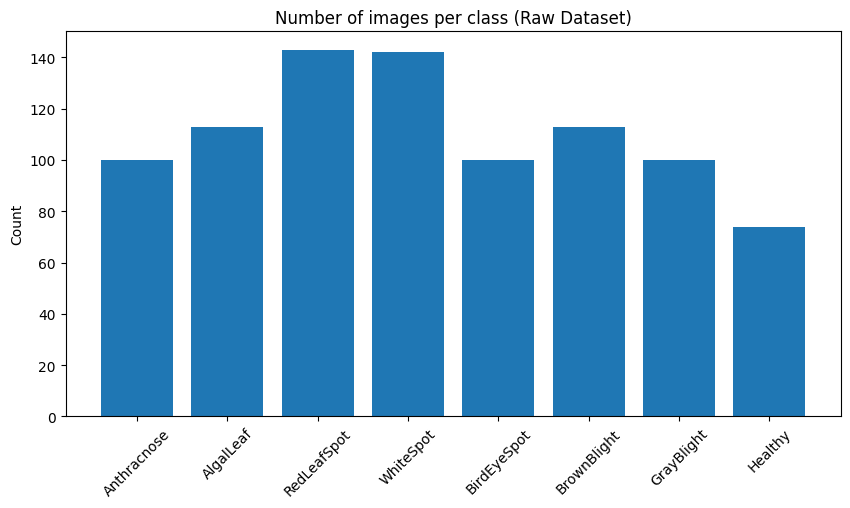

{'Anthracnose': 100, 'AlgalLeaf': 113, 'RedLeafSpot': 143, 'WhiteSpot': 142, 'BirdEyeSpot': 100, 'BrownBlight': 113, 'GrayBlight': 100, 'Healthy': 74}


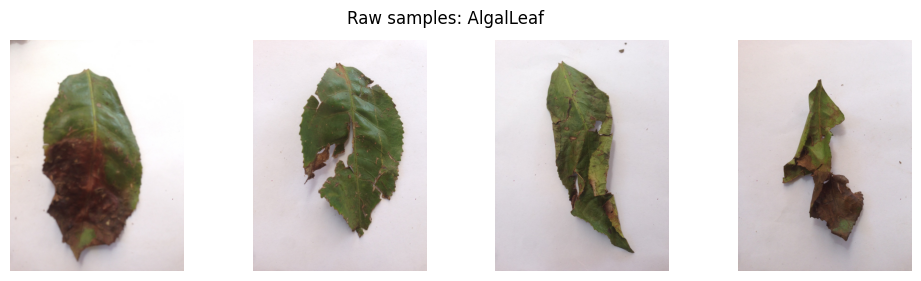

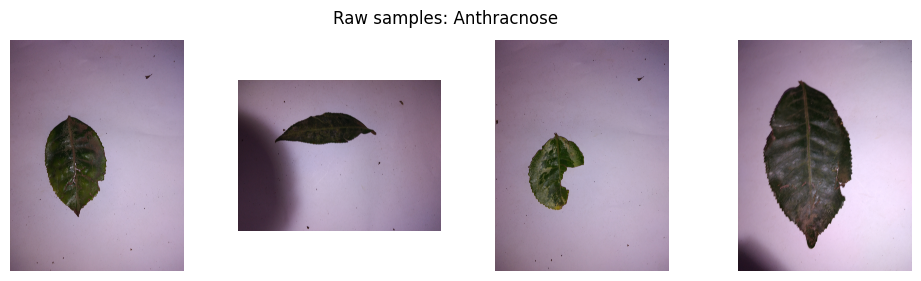

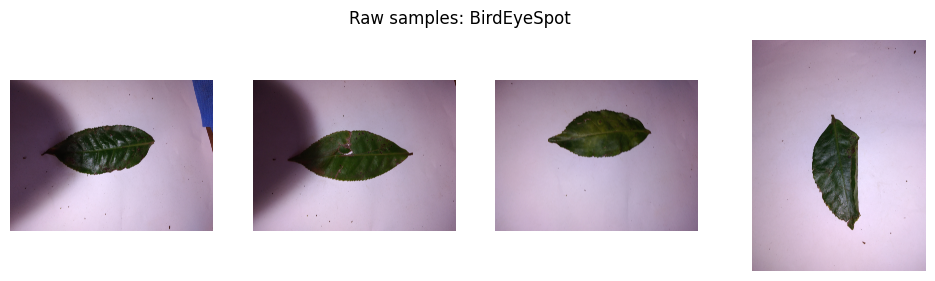

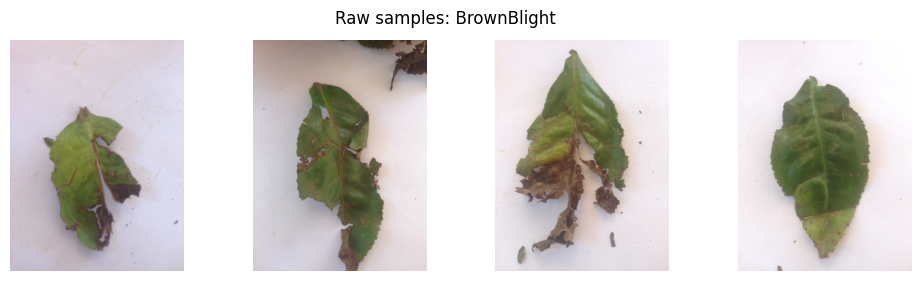

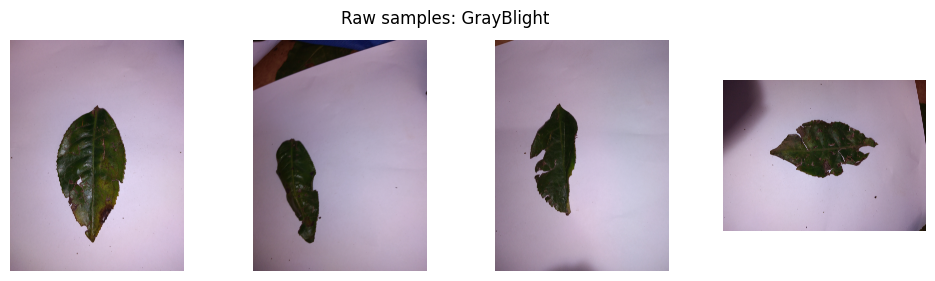

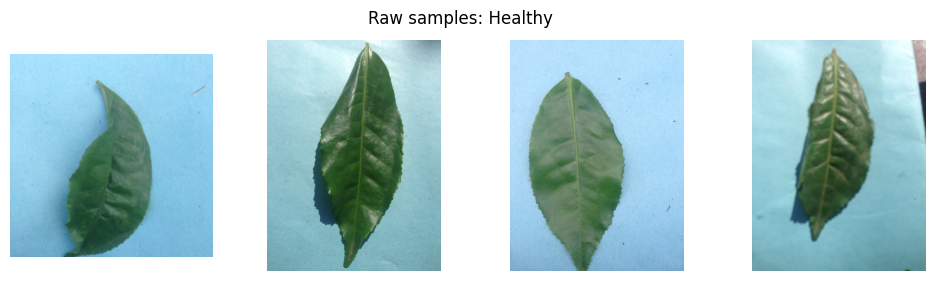

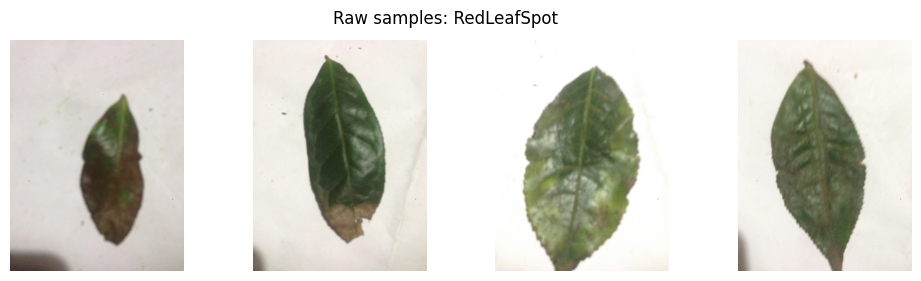

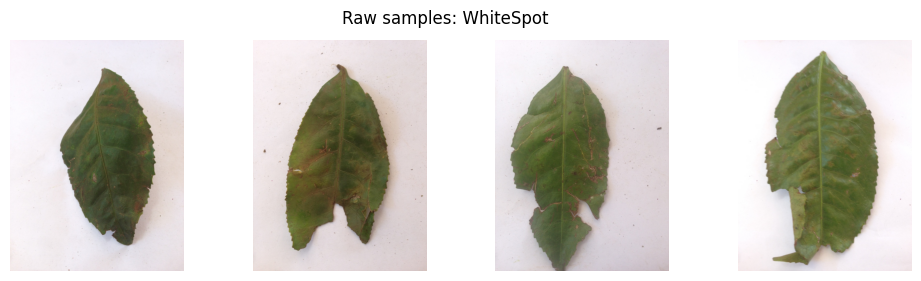

In [4]:
import random
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

def show_samples_raw(dataset_dir, n=4):
    classes = sorted(os.listdir(dataset_dir))
    for cls in classes:
        cls_path = os.path.join(dataset_dir, cls)
        if not os.path.isdir(cls_path):
            continue

        imgs = random.sample(os.listdir(cls_path), n)
        plt.figure(figsize=(12,3))
        for i, img_name in enumerate(imgs):
            img_path = os.path.join(cls_path, img_name)
            img = image.load_img(img_path)
            plt.subplot(1,n,i+1)
            plt.imshow(img)
            plt.axis("off")
        plt.suptitle(f"Raw samples: {cls}")
        plt.show()

show_samples_raw(dataset_dir)


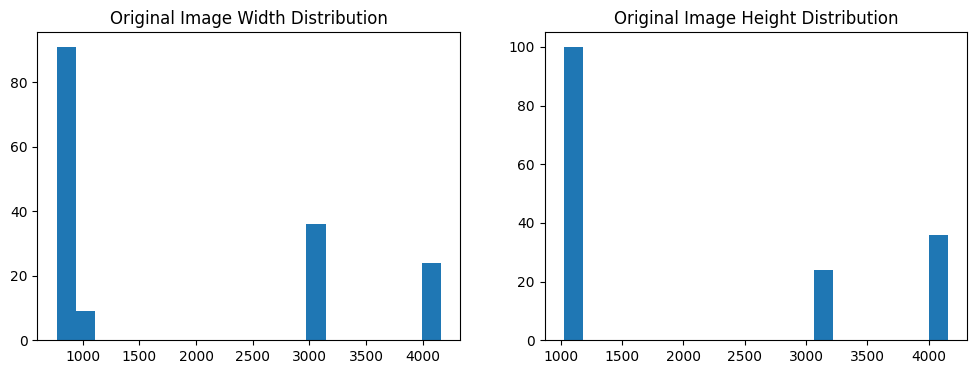

In [5]:
from PIL import Image
import random

sizes = []

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    imgs = random.sample(os.listdir(cls_path), min(20, len(os.listdir(cls_path))))
    for img_name in imgs:
        img_path = os.path.join(cls_path, img_name)
        with Image.open(img_path) as im:
            sizes.append(im.size)

widths = [s[0] for s in sizes]
heights = [s[1] for s in sizes]

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(widths, bins=20)
plt.title("Original Image Width Distribution")

plt.subplot(1,2,2)
plt.hist(heights, bins=20)
plt.title("Original Image Height Distribution")
plt.show()


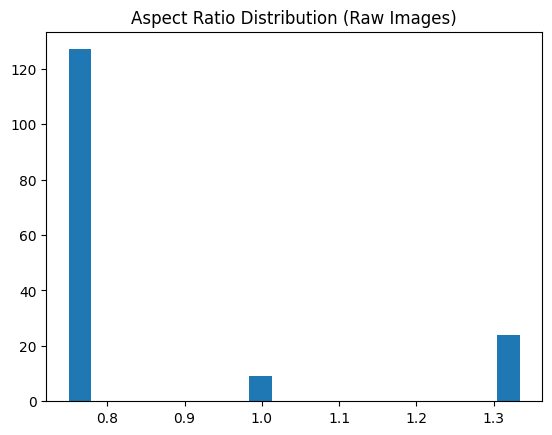

In [6]:
ratios = [w/h for w,h in sizes]

plt.hist(ratios, bins=20)
plt.title("Aspect Ratio Distribution (Raw Images)")
plt.show()


In [7]:
bad_files = []

for cls in os.listdir(dataset_dir):
    cls_path = os.path.join(dataset_dir, cls)
    if not os.path.isdir(cls_path):
        continue

    for f in os.listdir(cls_path):
        path = os.path.join(cls_path, f)
        try:
            with Image.open(path) as im:
                im.verify()
        except:
            bad_files.append(path)

print("Corrupted images:", len(bad_files))


Corrupted images: 0
